# Этап 6. Эпизоды: исходы, пробег, «лишние» срабатывания фильтра

Код: `classify_outcome`, `run_episode` в `rssrl/scenarios.py`; `interventions`, `counterfactual`, `counterfactual_grid` в `rssrl/pilot.py`. Проверки: `tests/test_episodes.py`.

**Исход эпизода** (highway-v0 ограничен 40 с), в порядке приоритета:
- *столкновение* — агент столкнулся (эпизод на этом заканчивается);
- *съезд с дороги* — агент хотя бы раз оказался вне дороги;
- *остановка* — агент стоял (скорость < 0,5 м/с) не меньше 2 с подряд;
- *безопасно* — доехал до конца времени без всего перечисленного.

**Пробег** — сколько агент проехал по факту, до конца времени или до столкновения.

**Контрфактическая проверка.** Каждое вмешательство фильтра (торможение или запрет/отмена перестроения) проверяем так: заново прогоняем ту же сцену с той же политикой, но с момента вмешательства фильтр отключен — на все время вмешательства и еще 5 с после. До этого момента прогон совпадает с исходным (сцена детерминирована своим seed — это проверяет тест). Если в этом окне агент столкнулся бы — вмешательство **нужное**, если нет — **лишнее**.

Вмешательства с перерывом меньше 1 с считаем одним: иначе «дребезг» фильтра на границе d_min (+3/−4 м/с² через шаг) дал бы сотни коротких вмешательств.

Фильтр: d_min — лемма 2 с учетом рывка 10 м/с³. Нарушение (тормозящий лидер, подрезание) — по расписанию из эталонного прогона, одинаковое для всех вариантов агента.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid, counterfactual_grid, _run_one, MERGE_GAP, CF_HORIZON

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_06'  # таблицы пилота, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SEEDS = range(20)
# основной режим — фильтр с задержкой ρ, дополнительный — мгновенный фильтр
VARIANTS = [(True, 0.5), (True, 0.0), (False, 0.5)]
NAMES = {(True, 0.5): 'фильтр, задержка ρ (основной)', (True, 0.0): 'фильтр, задержка 0 (доп.)',
         (False, 0.5): 'без фильтра'}
# (сценарий, уровни, политика, подпись)
SETUPS = [
    ('nominal', [1.0], 'idle', 'номинальный, IDLE'),
    ('nominal', [1.0], 'random', 'номинальный, случайная'),
    ('brake', [1.0, 2.0], 'idle', 'тормозящий лидер, IDLE'),
    ('cutin', [1.0, 0.25], 'idle', 'подрезание, IDLE'),
]

## Исходы эпизодов и пробег

In [2]:
frames, LOGS = [], {}
for kind, levels, policy, label in SETUPS:
    o, logs = run_grid(SEEDS, levels, VARIANTS, kind=kind, policy=policy, trigger='schedule')
    o['сценарий'] = label
    o['уровень'] = o['gamma'] if kind == 'cutin' else o['beta']
    frames.append(o)
    LOGS[label] = (kind, policy, logs)
outcomes = pd.concat(frames, ignore_index=True)
outcomes['вариант'] = [NAMES[(s, d)] for s, d in zip(outcomes['shield'], outcomes['reaction_delay'])]
outcomes.drop(columns=['crash_partners']).to_csv(PILOT / 'outcomes.csv', index=False)

table = (outcomes.groupby(['сценарий', 'уровень', 'вариант'], sort=False)['outcome']
         .value_counts().unstack(fill_value=0)
         .reindex(columns=['safe', 'stopped', 'offroad', 'collision'], fill_value=0)
         .rename(columns={'safe': 'безопасно', 'stopped': 'остановка',
                          'offroad': 'съезд', 'collision': 'столкновение'}))
table['пробег, км (среднее)'] = outcomes.groupby(['сценарий', 'уровень', 'вариант'], sort=False)['distance_km'].mean().round(3)
table

outcome                                                       безопасно  \
сценарий               уровень вариант                                    
номинальный, IDLE      1.00    фильтр, задержка ρ (основной)         20   
                               фильтр, задержка 0 (доп.)             20   
                               без фильтра                            2   
номинальный, случайная 1.00    фильтр, задержка ρ (основной)         20   
                               фильтр, задержка 0 (доп.)             20   
                               без фильтра                            4   
тормозящий лидер, IDLE 1.00    фильтр, задержка ρ (основной)          3   
                               фильтр, задержка 0 (доп.)              3   
                               без фильтра                            1   
                       2.00    фильтр, задержка ρ (основной)          3   
                               фильтр, задержка 0 (доп.)              3   
                               без фильтра                            1   
подрезание, IDLE       1.00    фильтр, задержка ρ (основной)          6   
                               фильтр, задержка 0 (доп.)              6   
                               без фильтра                            0   
                       0.25    фильтр, задержка ρ (основной)          5   
                               фильтр, задержка 0 (доп.)              7   
                               без фильтра                            0   

outcome                                                       остановка  \
сценарий               уровень вариант                                    
номинальный, IDLE      1.00    фильтр, задержка ρ (основной)          0   
                               фильтр, задержка 0 (доп.)              0   
                               без фильтра                            0   
номинальный, случайная 1.00    фильтр, задержка ρ (основной)          0   
                               фильтр, задержка 0 (доп.)              0   
                               без фильтра                            0   
тормозящий лидер, IDLE 1.00    фильтр, задержка ρ (основной)         17   
                               фильтр, задержка 0 (доп.)             17   
                               без фильтра                            0   
                       2.00    фильтр, задержка ρ (основной)         17   
                               фильтр, задержка 0 (доп.)             17   
                               без фильтра                            0   
подрезание, IDLE       1.00    фильтр, задержка ρ (основной)         14   
                               фильтр, задержка 0 (доп.)             14   
                               без фильтра                            0   
                       0.25    фильтр, задержка ρ (основной)         15   
                               фильтр, задержка 0 (доп.)             13   
                               без фильтра                            0   

outcome                                                       съезд  \
сценарий               уровень вариант                                
номинальный, IDLE      1.00    фильтр, задержка ρ (основной)      0   
                               фильтр, задержка 0 (доп.)          0   
                               без фильтра                        0   
номинальный, случайная 1.00    фильтр, задержка ρ (основной)      0   
                               фильтр, задержка 0 (доп.)          0   
                               без фильтра                        0   
тормозящий лидер, IDLE 1.00    фильтр, задержка ρ (основной)      0   
                               фильтр, задержка 0 (доп.)          0   
                               без фильтра                        0   
                       2.00    фильтр, задержка ρ (основной)      0   
                               фильтр, задержка 0 (доп.)          0   
                               без фильтра                        0   
подр

Как читать таблицу (уровень — β для тормозящего лидера, γ для подрезания, в номинальном режиме не используется):
- **С фильтром столкновений нет ни в одном сценарии**, ни при одной задержке (d_min с учетом рывка). Без фильтра — 16–20 из 20.
- **Остановка** — главный исход с фильтром в сценах с нарушителем: нарушитель останавливается и стоит, IDLE с фильтром останавливается за ним и стоит до конца эпизода (17 из 20 у тормозящего лидера, 13–15 из 20 у подрезания). Это безопасно, но агент никуда не едет. Без категории «остановка» такие эпизоды попали бы в «безопасно» и приукрасили бы результат. С d_min леммы 2 как в статье на месте «остановок» при задержке ρ были столкновения (агент трогался и въезжал в стоящего).
- **Съезд с дороги** не встретился ни разу: агент highway-env перестраивается только между существующими полосами.
- **Пробег** меньше там, где агент врезается рано (без фильтра) или стоит.

## Контрфактическая проверка вмешательств

In [3]:
cf_frames = []
for label, (kind, policy, logs) in LOGS.items():
    cf = counterfactual_grid(logs, kind=kind, policy=policy, trigger='schedule')
    cf['сценарий'] = label
    cf_frames.append(cf)
cf = pd.concat(cf_frames, ignore_index=True)
cf['вариант'] = [NAMES[(True, d)] for d in cf['reaction_delay']]
cf['тип'] = np.where(cf['brake_steps'] > 0, 'торможение', 'только перестроение')
cf.drop(columns=['crash_partners']).to_csv(PILOT / 'counterfactual.csv', index=False)

cf_table = cf.groupby(['сценарий', 'level', 'вариант'], sort=False).agg(
    вмешательств=('needed', 'size'),
    нужных=('needed', 'sum'),
    длительность_с=('duration', 'mean'),
)
cf_table['доля нужных'] = (cf_table['нужных'] / cf_table['вмешательств']).round(2)
cf_table.round(1)

вмешательств  \
сценарий               level вариант                                       
номинальный, IDLE      1.00  фильтр, задержка ρ (основной)           320   
                             фильтр, задержка 0 (доп.)                31   
номинальный, случайная 1.00  фильтр, задержка ρ (основной)           214   
                             фильтр, задержка 0 (доп.)               163   
тормозящий лидер, IDLE 1.00  фильтр, задержка ρ (основной)           111   
                             фильтр, задержка 0 (доп.)                30   
                       2.00  фильтр, задержка ρ (основной)           116   
                             фильтр, задержка 0 (доп.)                30   
подрезание, IDLE       1.00  фильтр, задержка ρ (основной)           154   
                             фильтр, задержка 0 (доп.)                38   
                       0.25  фильтр, задержка ρ (основной)           140   
                             фильтр, задержка 0 (доп.)                45   

                                                            нужных  \
сценарий               level вариант                                 
номинальный, IDLE      1.00  фильтр, задержка ρ (основной)       2   
                             фильтр, задержка 0 (доп.)          21   
номинальный, случайная 1.00  фильтр, задержка ρ (основной)      48   
                             фильтр, задержка 0 (доп.)          38   
тормозящий лидер, IDLE 1.00  фильтр, задержка ρ (основной)      31   
                             фильтр, задержка 0 (доп.)          21   
                       2.00  фильтр, задержка ρ (основной)      49   
                             фильтр, задержка 0 (доп.)          21   
подрезание, IDLE       1.00  фильтр, задержка ρ (основной)      30   
                             фильтр, задержка 0 (доп.)          25   
                       0.25  фильтр, задержка ρ (основной)      35   
                             фильтр, задержка 0 (доп.)          35   

                                                            длительность_с  \
сценарий               level вариант                                         
номинальный, IDLE      1.00  фильтр, задержка ρ (основной)             0.9   
                             фильтр, задержка 0 (доп.)                21.2   
номинальный, случайная 1.00  фильтр, задержка ρ (основной)             1.0   
                             фильтр, задержка 0 (доп.)                 1.7   
тормозящий лидер, IDLE 1.00  фильтр, задержка ρ (основной)             5.1   
                             фильтр, задержка 0 (доп.)                22.1   
                       2.00  фильтр, задержка ρ (основной)             4.8   
                             фильтр, задержка 0 (доп.)                22.1   
подрезание, IDLE       1.00  фильтр, задержка ρ (основной)             2.9   
                             фильтр, задержка 0 (доп.)                16.3   
                       0.25  фильтр, задержка ρ (основной)             3.5   
                             фильтр, задержка 0 (доп.)                13.9   

                                                            доля нужных  
сценарий               level вариант                                     
номинальный, IDLE      1.00  фильтр, задержка ρ (основной)          0.0  
                             фильтр, задержка 0 (доп.)              0.7  
номинальный, случайная 1.00  фильтр, задержка ρ (основной)          0.2  
                             фильтр, задержка 0 (доп.)              0.2  
тормозящий лидер, IDLE 1.00  фильтр, задержка ρ (основной)          0.3  
                             фильтр, задержка 0 (доп.)              0.7  
                       2.00  фильтр, задержка ρ (основной)          0.4  
                             фильтр, задержка 0 (доп.)              0.7  
подрезание, IDLE       1.00  фильтр, задержка ρ (основной)          0.2  
                             фильтр, задержка 0 (доп.)              0.7  
                       0.25  филь

In [4]:
by_type = cf.groupby(['сценарий', 'тип'], sort=False).agg(
    вмешательств=('needed', 'size'), нужных=('needed', 'sum'))
by_type['доля нужных'] = (by_type['нужных'] / by_type['вмешательств']).round(2)
by_type

вмешательств  нужных  доля нужных
сценарий               тип                                                   
номинальный, IDLE      торможение                    351      23         0.07
номинальный, случайная торможение                    265      61         0.23
                       только перестроение           112      25         0.22
тормозящий лидер, IDLE торможение                    287     122         0.43
подрезание, IDLE       торможение                    377     125         0.33

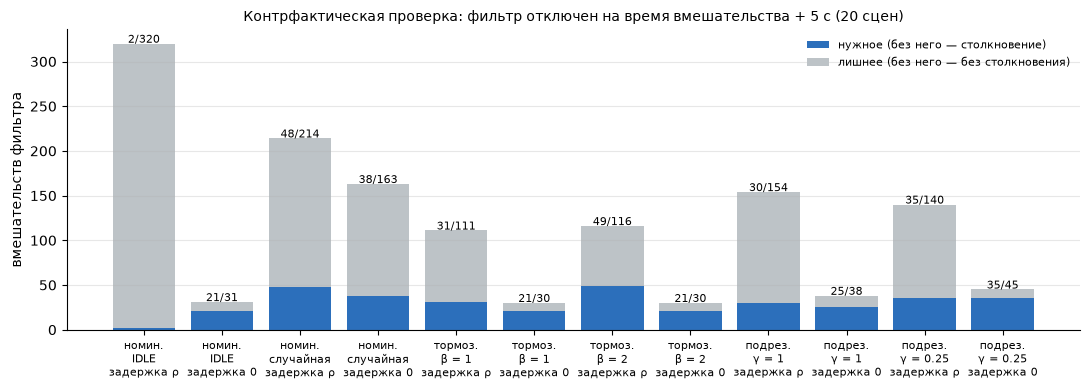

In [5]:
# доля нужных по сценариям и задержкам — столбики «нужные / лишние»
g = cf.groupby(['сценарий', 'level', 'reaction_delay'], sort=False)['needed'].agg(['sum', 'size']).reset_index()
SHORT = {'номинальный, IDLE': 'номин.\nIDLE', 'номинальный, случайная': 'номин.\nслучайная',
         'тормозящий лидер, IDLE': 'тормоз.\nβ = {:g}', 'подрезание, IDLE': 'подрез.\nγ = {:g}'}
g['подпись'] = [SHORT[s].format(l) + f"\nзадержка {'ρ' if d else '0'}"
              for s, l, d in zip(g['сценарий'], g['level'], g['reaction_delay'])]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(g))
ax.bar(x, g['sum'], color='#2c6fbb', label='нужное (без него — столкновение)')
ax.bar(x, g['size'] - g['sum'], bottom=g['sum'], color='#bdc3c7', label='лишнее (без него — без столкновения)')
for xi, (s, n) in enumerate(zip(g['sum'], g['size'])):
    ax.text(xi, n + 1, f'{s}/{n}', ha='center', fontsize=8)
ax.set_xticks(x, g['подпись'], fontsize=8)
ax.set_ylabel('вмешательств фильтра')
ax.legend(frameon=False, fontsize=8)
ax.set_title(f'Контрфактическая проверка: фильтр отключен на время вмешательства + {CF_HORIZON:g} с (20 сцен)', fontsize=10)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / '06_counterfactual.png', dpi=150)

Как читать:
- **Доля нужных сильно зависит от длины вмешательства.** С задержкой 0 у IDLE вмешательства длинные (14–22 с: слитый «дребезг» за машиной впереди), и без них агент врезается — нужных 70–80 %. С задержкой ρ фильтр тормозит короткими отрезками (≈ 1 с в номинальном режиме) с перерывами больше 1 с: за ρ агент успевает отъехать от границы d_min, и вмешательства не сливаются. Без одного такого отрезка агент за окно 5 с обычно не успевает врезаться — в номинальном режиме нужных всего 2 из 320. Это не значит, что фильтр с задержкой ρ не нужен (без фильтра столкновений 18 из 20): контрфакт отключает фильтр только на одно вмешательство + 5 с.
- **Случайная политика** — нужных около 20 %, в основном лишние запреты перестроений и короткие торможения.
- **Тормозящий лидер и подрезание** при задержке ρ — нужных 20–40 %, при задержке 0 — 70–80 %.
Вывод для методики: метрику «доля лишних срабатываний» нужно считать с одним и тем же правилом слияния и окном для всех вариантов и указывать оба параметра в статье; сравнивать ее между задержками 0 и ρ напрямую некорректно.

Откуда у IDLE лишние вмешательства: смотрим, когда они начинаются и сколько длятся.

In [6]:
idle = cf[cf['сценарий'].str.contains('IDLE')]
idle.groupby('needed').agg(
    вмешательств=('t_start', 'size'),
    начались_в_первые_3_с=('t_start', lambda t: int((t < 3).sum())),
    медиана_длительности_с=('duration', 'median'),
).rename(index={False: 'лишние', True: 'нужные'})

,вмешательств,начались_в_первые_3_с,медиана_длительности_с
needed,,,
лишние,745,92,0.933333
нужные,270,48,17.433333


Лишних у IDLE много за счет коротких торможений при задержке ρ (медиана длительности лишнего ≈ 0,9 с, нужного — ≈ 17 с). В первые 3 с начинается только малая часть лишних (92 из 745): это не столько стартовая расстановка, сколько повторяющиеся короткие торможения на границе d_min. Для экспериментов по-прежнему разумно не считать вмешательства в первые 3 с.

## Пример «лишнего» торможения: исходный прогон и прогон без вмешательства

сценарий       номинальный, случайная
seed                               12
t_start                          21.6
t_end                       29.466667
brake_steps                        63
lc_steps                            2
min_gap                      7.023364
Name: 602, dtype: object

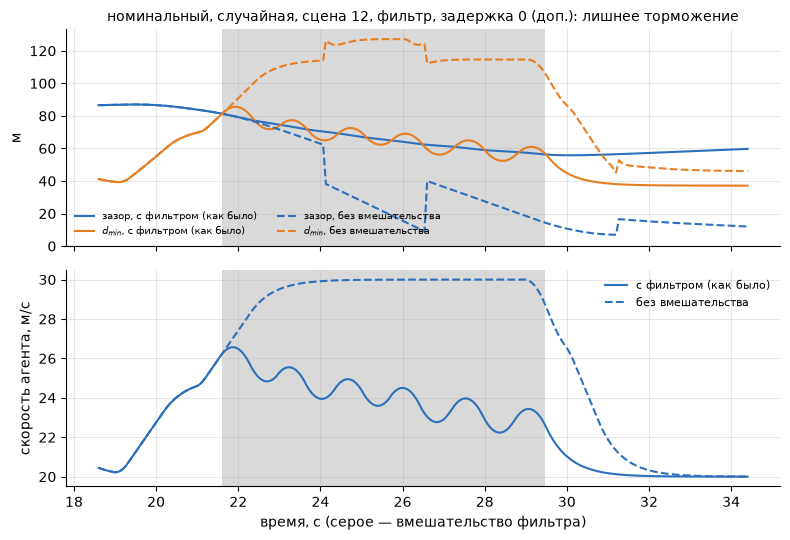

In [7]:
extra = cf[(~cf.needed) & (cf['тип'] == 'торможение') & (cf.duration > 0.5)].sort_values('duration', ascending=False)
ex = extra.iloc[0]
kind, policy, logs = LOGS[ex['сценарий']]
job = (int(ex.seed), ex.level, True, ex.reaction_delay)
orig = logs[job]
_, cf_log = _run_one(job, kind, policy, shield_off_at=ex.t_start, t_stop=ex.t_end + CF_HORIZON, trigger='schedule')
lo, hi = ex.t_start - 3, ex.t_end + CF_HORIZON
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
for log, style, name in [(orig, '-', 'с фильтром (как было)'), (cf_log, '--', 'без вмешательства')]:
    w = log[(log.t >= lo) & (log.t <= hi)]
    axes[0].plot(w.t, w.gap.where(w.gap < 1e6), style, color='#2c6fbb', label=f'зазор, {name}')
    axes[0].plot(w.t, w.d_min.where(w.gap < 1e6), style, color='#e67e22', label=f'$d_{{min}}$, {name}')
    axes[1].plot(w.t, w.ego_v, style, color='#2c6fbb', label=name)
for ax in axes:
    ax.axvspan(ex.t_start, ex.t_end, color='0.85', linewidth=0)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('м'); axes[0].set_ylim(bottom=0)
axes[1].set_ylabel('скорость агента, м/с')
axes[1].set_xlabel('время, с (серое — вмешательство фильтра)')
axes[0].legend(fontsize=7, frameon=False, ncol=2)
axes[1].legend(fontsize=8, frameon=False)
axes[0].set_title(f"{ex['сценарий']}, сцена {int(ex.seed)}, {NAMES[(True, ex.reaction_delay)]}: лишнее торможение", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '06_extra_intervention.png', dpi=150)
ex[['сценарий', 'seed', 't_start', 't_end', 'brake_steps', 'lc_steps', 'min_gap']]

Без вмешательства зазор опускается ниже d_min (по RSS ситуация опасная), но столкновения не происходит: машина впереди не тормозит изо всех сил. Это и есть смысл «лишнего» срабатывания: RSS страхует от худшего случая, который в этот раз не наступил. «Лишнее» здесь — не ошибка фильтра, а цена гарантии.

## Ограничения этой проверки (для статьи)

1. Окно — время вмешательства + 5 с. Столкновение позже окна не учитывается; при большем окне доля нужных была бы выше.
2. Вмешательства с перерывом меньше 1 с объединены. У IDLE это дает длинные вмешательства (десятки секунд), и вердикт «нужное» относится ко всему отрезку.
3. Контрфакт отвечает на вопрос «было бы столкновение», а не «была бы опасная по RSS ситуация». Второе почти всегда «да» — фильтр срабатывает только при опасности.
4. Политика в контрфакте та же (IDLE или та же последовательность случайных действий). Для PPO надо будет запрашивать политику по наблюдениям контрфактического прогона — `run_episode` это уже позволяет.

## Выводы этапа 6

1. Исходы эпизодов разделены на четыре категории. С фильтром (d_min с учетом рывка) столкновений нет ни в одном сценарии; «остановка» — главный исход в сценах с нарушителем (агент стоит за остановившимся нарушителем).
2. Пробег считается по факту и есть в таблице исходов.
3. Контрфактическая проверка работает (с расписанием нарушения сцена до момента отключения фильтра совпадает с исходной — это проверяет тест), но доля «нужных» сильно зависит от правила слияния вмешательств (1 с) и окна (5 с): при задержке ρ вмешательства короткие, и большинство выглядят «лишними». Эти параметры надо зафиксировать до основного эксперимента и обсудить с преподавателем.